# Biểu đồ 1 — Mean AI Exposure theo cluster  

Mục đích: so sánh mean AI Exposure của bốn cluster với mean tổng thể 0.8416. Đường ngang là mốc tham chiếu để thấy cụm nào cao hơn hoặc thấp hơn mặt bằng chung.
Code

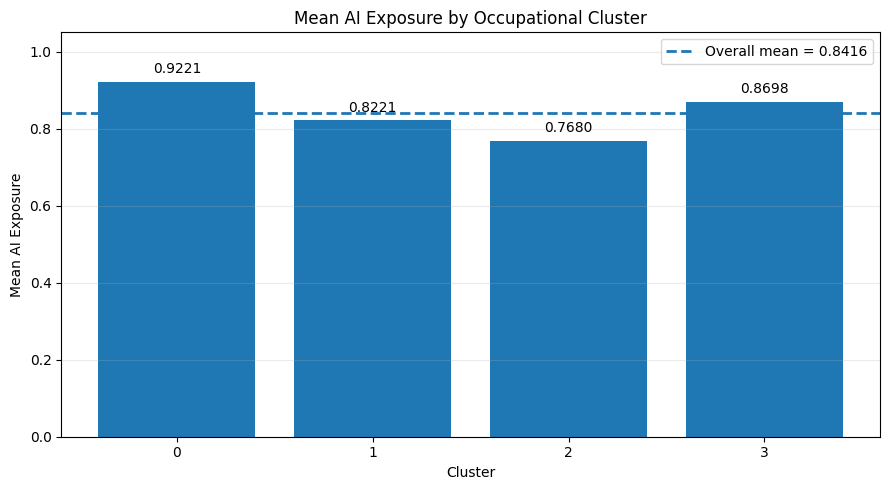

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3
from pathlib import Path

# 1. Đọc dữ liệu đã có nhãn cluster
DB_PATH = Path("../data/database/career.db")

# Đổi đường dẫn này thành file thực tế đang lưu nhãn cluster của bạn
CLUSTER_PATH = Path("../outputs/kmeans_experiments/work_activities_41_lv_k4.csv")

cluster_labels = pd.read_csv(CLUSTER_PATH)

# File nhãn cần có 2 cột: occupation_code và cluster
conn = sqlite3.connect(DB_PATH)

exposure = pd.read_sql_query("""
    SELECT occupation_code, ai_exposure_score
    FROM occupations
""", conn)

conn.close()

# 2. Ghép nhãn cluster với AI Exposure
data = cluster_labels[
    ["occupation_code", "cluster_id"]
].merge(
    exposure,
    on="occupation_code",
    how="left",
    validate="one_to_one"
)

# Chỉ sử dụng các nghề có AI Exposure hợp lệ
valid_data = data.dropna(subset=["ai_exposure_score"]).copy()

# 3. Tính mean theo cluster và mean toàn bộ mẫu hợp lệ
cluster_mean = (
    valid_data.groupby("cluster_id")["ai_exposure_score"]
    .mean()
    .sort_index()
)

overall_mean = valid_data["ai_exposure_score"].mean()

# 4. Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    cluster_mean.index.astype(str),
    cluster_mean.values
)

ax.axhline(
    overall_mean,
    linestyle="--",
    linewidth=2,
    label=f"Overall mean = {overall_mean:.4f}"
)

# Hiển thị giá trị trên đầu mỗi cột
ax.bar_label(bars, fmt="%.4f", padding=4)

ax.set_title("Mean AI Exposure by Occupational Cluster")
ax.set_xlabel("Cluster")
ax.set_ylabel("Mean AI Exposure")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Biểu đồ 3 — Coverage AI Exposure theo cluster  

Mục đích: thể hiện tỷ lệ nghề có dữ liệu AI Exposure hợp lệ trong tổng số nghề của từng cluster.

,total_occupations,occupations_with_exposure,coverage_pct
cluster_id,,,
0,204,198,97.06
1,221,210,95.02
2,258,247,95.74
3,228,224,98.25


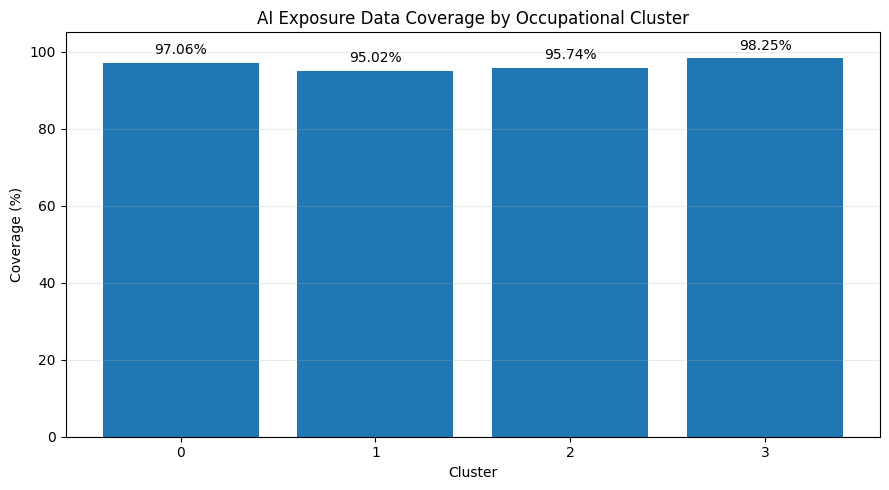

In [5]:
# 1. Tổng số nghề và số nghề có AI Exposure theo cluster
coverage = (
    data.groupby("cluster_id")
    .agg(
        total_occupations=("occupation_code", "nunique"),
        occupations_with_exposure=("ai_exposure_score", "count")
    )
    .sort_index()
)

coverage["coverage_pct"] = (
    coverage["occupations_with_exposure"]
    / coverage["total_occupations"]
    * 100
)

display(coverage.round(2))

# 2. Vẽ biểu đồ coverage
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    coverage.index.astype(str),
    coverage["coverage_pct"]
)

ax.bar_label(
    bars,
    labels=[f"{v:.2f}%" for v in coverage["coverage_pct"]],
    padding=4
)

ax.set_title("AI Exposure Data Coverage by Occupational Cluster")
ax.set_xlabel("Cluster")
ax.set_ylabel("Coverage (%)")
ax.set_ylim(0, 105)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()